Ngưỡng tìm được:  96.68656001366806


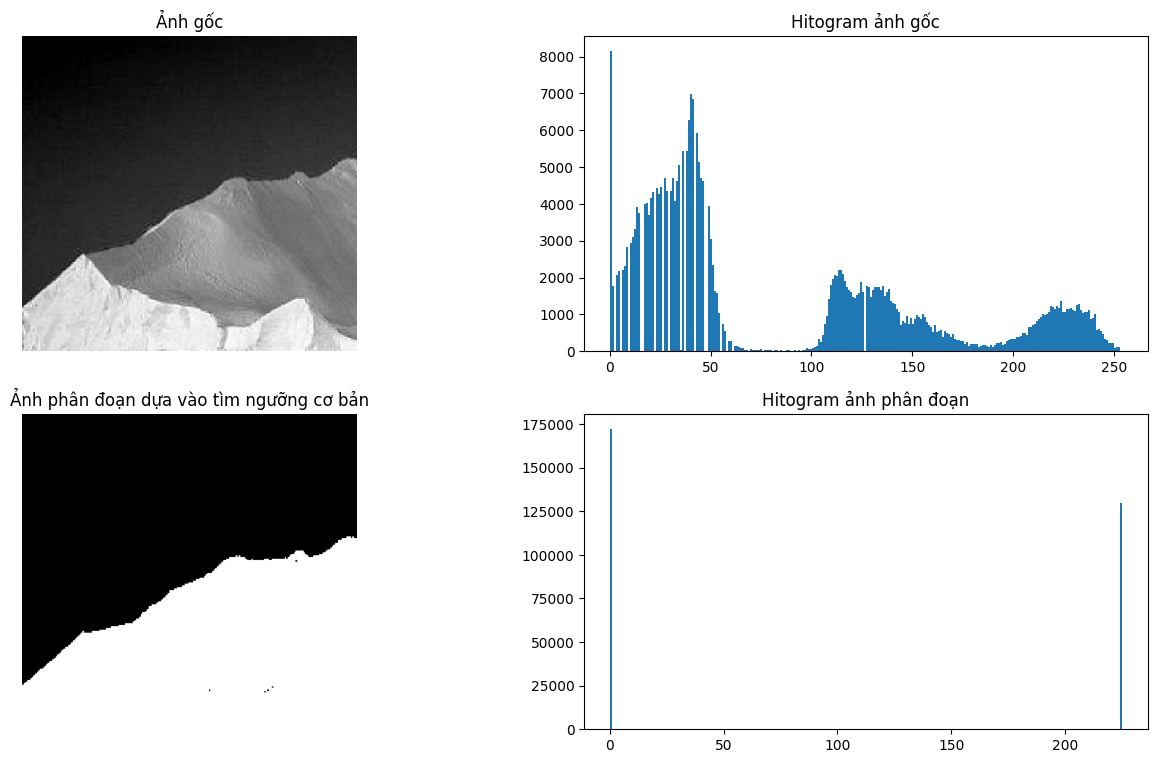

In [4]:
# Phân đoạn ảnh bằng kỹ thuật cắt ngưỡng theo 1 ngưỡng toàn cục (global)
# Phân đoạn ảnh bằng cắt ngưỡng được với ngưỡng tìm được bằng thuật toán tìm ngưỡng toàn cục cơ bản
import cv2
import numpy as np
from matplotlib import pyplot as plt

def Tim_nguong_toan_cuc(img): # Định nghĩa hàm tìm ngưỡng
    #Bước 1. Khởi tạo ngưỡng ban đầu t bằng giá trị trung bình mức xám của ảnh
    t=np.mean(img) #initial condition
    g1 = []  # Định nghĩa nhóm g1
    g2 = []  # Định nghĩa nhóm g2
    m,n = img.shape
    # Lặp để tính ngưỡng
    while (True):
        # Bước 2. Tạo nhóm g1,g2 dựa trên ngưỡng t
        for i in range(m):
            for j in range(n):
                if (img[i,j] < t):
                    g1.append(img[i,j])
                else:
                    g2.append(img[i,j])
        # Bước 3. Tính trung bình mức xám trong vùng g1,g2
        mu1 = np.mean(g1)
        mu2 = np.mean(g2)
        # Bước 4. Tính lại ngưỡng t có giá trị mới
        t = ((mu1+ mu2)/2)
        # Tính delta t để làm điều kiện thoát vòng lặp
        t0 = t
        delta_t = abs(t-t0)
        if(delta_t < 1):
            break
    print("Ngưỡng tìm được: ",t)
    return t

def phan_doan_bang_cat_nguong(img,nguong): # Định nghĩa hàm phân đoạn bằng cắt ngưỡng
    m, n = img.shape
    img_phan_doan_cat_nguong = np.zeros([m, n])
    for i in range(m):
        for j in range(n):
            if (img[i,j] < nguong):
                img_phan_doan_cat_nguong[i,j] = 0
            else:
                img_phan_doan_cat_nguong[i,j] = 225   # tương đương giá trị 1 trong trong công thức
    return img_phan_doan_cat_nguong

if __name__ == "__main__":
    # reading image in gray scale
    img_goc = cv2.imread("test2.tif",0)

    # gọi ham để phân đoạn bằng cắt ngưỡng toàn cục dựa trên ngưỡng
    T = Tim_nguong_toan_cuc(img_goc)
    img_phan_doan = phan_doan_bang_cat_nguong(img_goc,T)

    # Vẽ và hiển thị ảnh gốc, histogram ảnh gốc và ảnh phân đoạn
    fig2 = plt.figure(figsize=(16, 9))  # Tạo vùng vẽ tỷ lệ 16:9
    #Tạo 4 vùng vẽ con
    (ax1, ax2), (ax3, ax4) = fig2.subplots(2, 2)
    # Hiển thị ảnh gốc
    ax1.imshow(img_goc, cmap='gray')
    ax1.set_title('Ảnh gốc')
    ax1.axis('off')

    # Hiển thị histogram ảnh gốc
    ax2.hist(img_goc.flatten(),bins=256)
    ax2.set_title('Hitogram ảnh gốc')

    # Hiển thị ảnh phân đoạn
    ax3.imshow(img_phan_doan, cmap='gray')
    ax3.set_title('Ảnh phân đoạn dựa vào tìm ngưỡng cơ bản')
    ax3.axis('off')

    # Hiển thị histogram ảnh phân đoạn
    ax4.hist(img_phan_doan.flatten(), bins=256)
    ax4.set_title('Hitogram ảnh phân đoạn')
    plt.show()


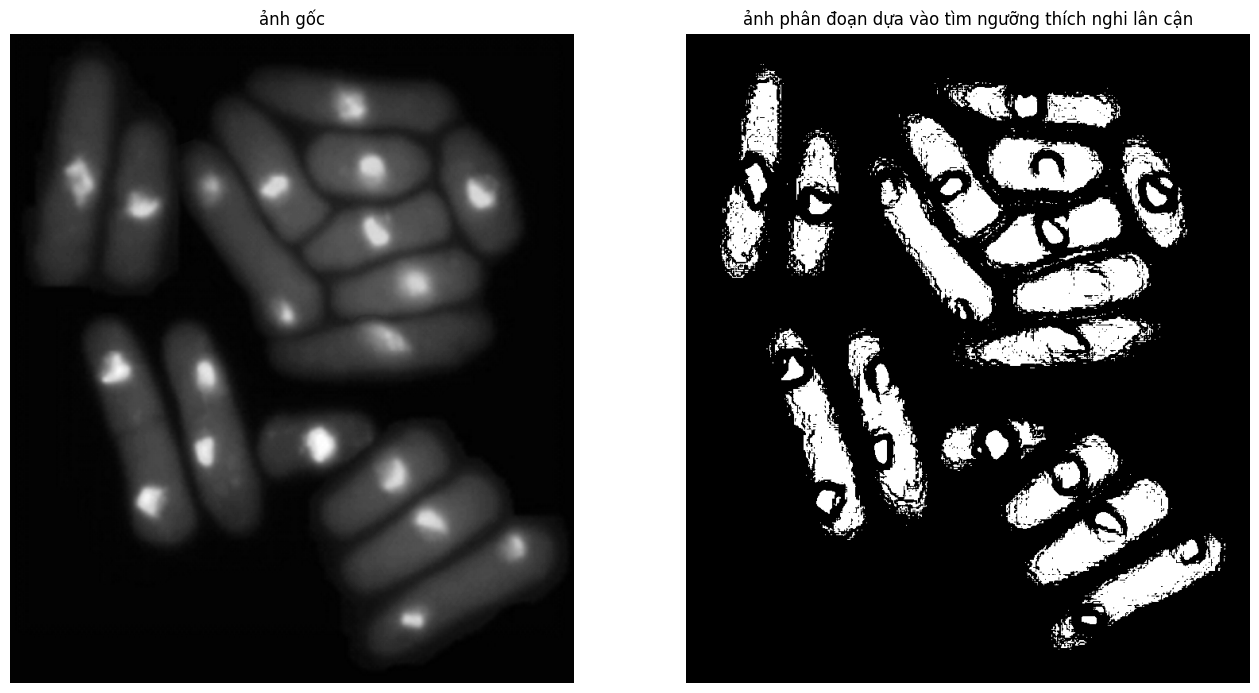

In [1]:
# Phân đoạn ảnh bằng cắt ngưỡng thích nghi dựa trên Thuộc tính vùng ảnh cục bộ (adaptive)
import numpy as np
import cv2
import matplotlib.pyplot as plt

def Phan_doan_lan_can(img, ksize):
    m, n = img.shape
    img_ket_qua_phan_doan = np.zeros([m, n])
    h=(ksize -1) // 2
    a=20
    b=1
    padded_img = np.pad(img, (h, h), mode='reflect')
    mG = np.mean(padded_img)   # Bước 1. Tính trung bình mức xám ảnh
    for i in range(m):
        for j in range(n):
            vung_anh_kich_thuoc_k = padded_img[i:i+ksize,j:j+ksize]
            Do_lech_chuan = np.std(vung_anh_kich_thuoc_k) # Bước 1. Tính độ lệch chuẩn cục bộ
            T= a*Do_lech_chuan + b*mG   # Bước 2. Tính ngưỡng theo công thức 9
            if padded_img[i, j] > T:    # Bước 3. Cắt ngưỡng theo công thức 10
                img_ket_qua_phan_doan[i, j] = 255
            else:
                img_ket_qua_phan_doan[i, j] = 0
    return img_ket_qua_phan_doan

if __name__ == "__main__":
    img_goc = cv2.imread('test1.tif', 0)


    ksize =3
    img_ket_qua = Phan_doan_lan_can(img_goc, ksize)

    fig = plt.figure(figsize=(16, 9))     # Thiết lập vùng (cửa sổ) vẽ
    (ax1, ax2) = fig.subplots(1, 2)        # Thiết lập 2 vùng con ax1, ax2
    ax1.imshow(img_goc, cmap='gray')      # Hiển thị ảnh gốc vùng ax1
    ax1.set_title("ảnh gốc")  # Thiết lập tiêu đề vùng ax1
    ax1.axis("off")

    ax2.imshow(img_ket_qua, cmap='gray')  # Hiển thị ảnh sau khi lọc
    ax2.set_title("ảnh phân đoạn dựa vào tìm ngưỡng thích nghi lân cận") # Thiết lập tiêu đề vùng ax2
    ax2.axis("off")

    plt.show()

Ngưỡng tìm được 97


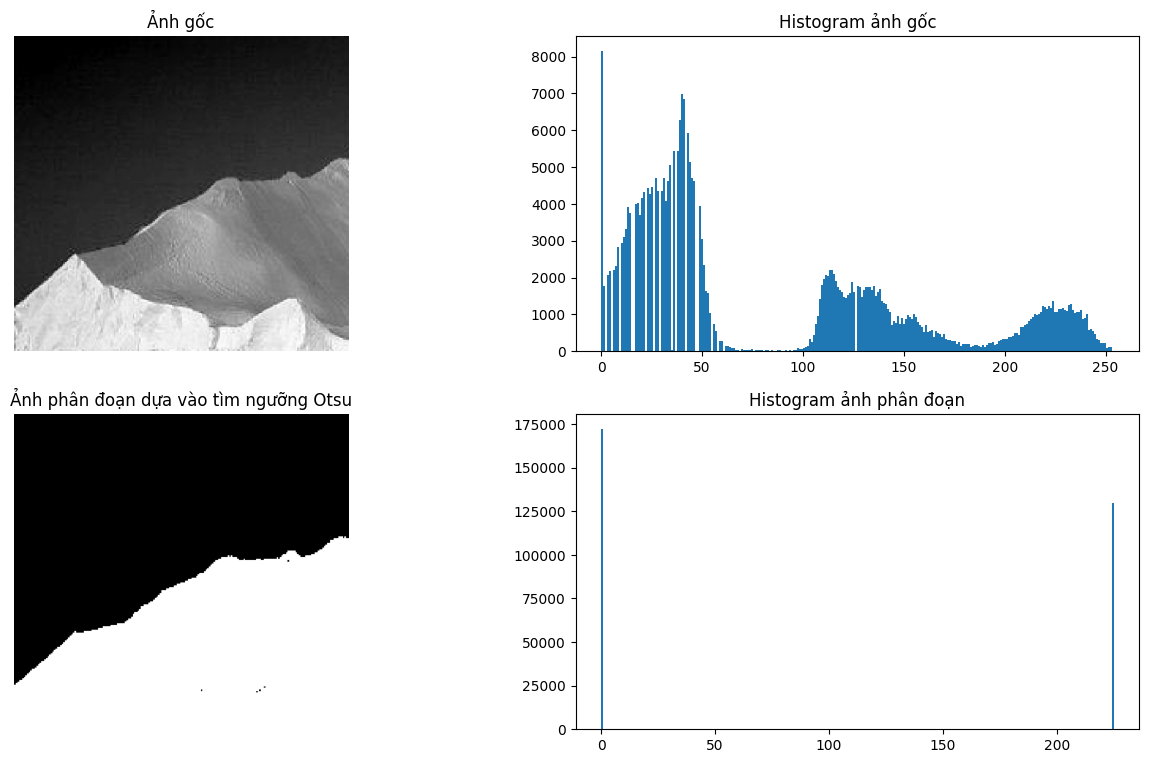

In [3]:
#otsu
import cv2
import numpy as np
from matplotlib import pyplot as plt
def otsu(img):
    phuong_sai_t = 0 # Khởi tạo biến phuong_sai_t lưu giá trị phương sai để so sánh
                     # giá trị phương sai thuật toán tính được để xác định
                     # phương sai cực đại, trên cơ sở đó xác định ngưỡng tối ưu cần tìm
    M,N = img.shape
    mG = np.mean(img)   # Tính mG giá trị trung bình mức xám của ảnh theo công thức 6

    for nguong in range(256):
        Tong_gt_xam_A = 1  #Khởi tạo biến lưu tổng giá trị mức xám của nhóm A
        Tong_gt_xam_B = 1  #Khởi tạo biến lưu tổng giá trị mức xám của nhóm A
        Tong_pixel_A = 1    #Khởi tạo biến lưu tổng số pixel ở nhóm A
        Tong_pixel_B = 1    #Khởi tạo biến lưu tổng số pixel ở nhóm B
        for i in range(M):  #Duyệt qua giá trị xám của mỗi pixel của hình ảnh gốc
            for j in range(N):
                if (img[i,j] >= nguong):  #Nếu pixel có giá trị màu xám > = nguong (nhóm A)
                    Tong_pixel_A = Tong_pixel_A + 1  #Lấy tổng số pixel của phần A
                    Tong_gt_xam_A = Tong_gt_xam_A + img[i,j] # Lấy tổng giá trị xám của nhóm A
                else:     #Nếu pixel có giá trị xám < nguong (nhóm B)
                    Tong_pixel_B = Tong_pixel_B + 1  #Lấy tổng số pixel của nhóm B
                    Tong_gt_xam_B = Tong_gt_xam_B + img[i,j] # Lấy tổng giá trị xám của nhóm B

        P1 = Tong_pixel_A/(M*N) # Tính P1(k) theo công thức 4 và 3
        P2 = Tong_pixel_B/(M*N) # Tính P2(k) theo công thức 4 và 3
        m1 = Tong_gt_xam_A/Tong_pixel_A # Tính m1(k) theo công thức 5
        m2 = Tong_gt_xam_B/Tong_pixel_B # Tính m2(k) theo công thức 5
        phuong_sai = P1*((m1-mG)**2)+P2*((m2-mG)**2) # Tính phương sai theo công thức 7

        if (phuong_sai > phuong_sai_t): # xác định phương sai tối đa theo công thức 8
            phuong_sai_t = phuong_sai
            nguong_toi_uu = nguong  # Để có được ngưỡng tối ưu của phương sai tối đa

    print("Ngưỡng tìm được", nguong_toi_uu)
    return nguong_toi_uu

def phan_doan_bang_cat_nguong(img,nguong): # Định nghĩa hàm phân đoạn bằng cắt ngưỡng
    m, n = img.shape
    img_phan_doan_cat_nguong = np.zeros([m, n])
    for i in range(m):
        for j in range(n):
            if (img[i,j] < nguong):
                img_phan_doan_cat_nguong[i,j] = 0
            else:
                img_phan_doan_cat_nguong[i,j] = 225 # tương đương gt 1 trong công thức 1
    return img_phan_doan_cat_nguong

if __name__ == "__main__":
    # reading image in gray scale
    img_goc = cv2.imread('test2.tif', 0)
    nguong= otsu(img_goc)
    img_phan_doan=phan_doan_bang_cat_nguong(img_goc,nguong)

    # Vẽ và hiển thị ảnh gốc, histogram ảnh gốc và ảnh phân đoạn
    fig2 = plt.figure(figsize=(16, 9))  # Tạo vùng vẽ tỷ lệ 16:9
    # Tạo 4 vùng vẽ con
    (ax1, ax2), (ax3, ax4) = fig2.subplots(2, 2)
    # Hiển thị ảnh gốc
    ax1.imshow(img_goc, cmap='gray')
    ax1.set_title('Ảnh gốc')
    ax1.axis('off')

    # Hiển thị histogram ảnh gốc
    ax2.hist(img_goc.flatten(), bins=256)
    ax2.set_title('Histogram ảnh gốc')

    # Hiển thị ảnh phân đoạn
    ax3.imshow(img_phan_doan, cmap='gray')
    ax3.set_title('Ảnh phân đoạn dựa vào tìm ngưỡng Otsu')
    ax3.axis('off')

    # Hiển thị histogram ảnh phân đoạn
    ax4.hist(img_phan_doan.flatten(), bins=256)
    ax4.set_title('Histogram ảnh phân đoạn')
    plt.show()
